# Machine Learning: End-to-End Data Preparation & Modeling Pipeline

This notebook demonstrates the **industry & academic standard workflow** for tabular data:
1. **Exploratory Data Inspection** (shapes, data types, missing values, class balance)
2. **Proper Train/Test Splitting** (strictly preventing data leakage and class imbalance)
3. **Robust Feature Preprocessing** with `ColumnTransformer` (handling numeric & categorical features)
4. **Building Leak-Free Pipelines** (`Pipeline` connecting preprocessor to estimators)
5. **Stratified Cross-Validation & Model Comparison** (Logistic Regression vs. Random Forest)
6. **Comprehensive Model Evaluation** (Accuracy, Precision, Recall, F1-Score, Confusion Matrix, ROC-AUC)
7. **Feature Importance & Interpretability**

In [1]:
# Core libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-Learn tools
from IPython.display import display
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Metrics & Visualization
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

# Display settings
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline
print("All libraries imported successfully!")


All libraries imported successfully!


## Step 1: Load and Inspect the Dataset
Before applying any transformations, we must thoroughly understand the raw data:
- What are the dimensions?
- Are there any missing (`NaN`) values?
- What data types are present (numerical vs. categorical)?
- Is the target variable balanced or imbalanced?

In [2]:
# Load the dataset as a Pandas DataFrame
raw_dataset = load_breast_cancer(as_frame=True)
data = raw_dataset.frame

# Separate feature matrix (X) and target vector (y)
X = data.drop(columns="target")
y = data["target"]

print(f"Samples: {X.shape[0]} | Features: {X.shape[1]}")
print(f"Target class names: {list(raw_dataset.target_names)} (0 = malignant, 1 = benign)\n")

# Check missing values
missing_total = X.isnull().sum().sum()
print(f"Total missing values across all features: {missing_total}")

# Check target class balance
class_counts = y.value_counts()
class_props = y.value_counts(normalize=True) * 100
balance_df = pd.DataFrame({
    "Class Name": [raw_dataset.target_names[i] for i in class_counts.index],
    "Count": class_counts.values,
    "Percentage (%)": class_props.values.round(2)
})
print("\nTarget Class Balance:")
display(balance_df)


Samples: 569 | Features: 30
Target class names: [np.str_('malignant'), np.str_('benign')] (0 = malignant, 1 = benign)

Total missing values across all features: 0

Target Class Balance:


,Class Name,Count,Percentage (%)
0,benign,357,62.74
1,malignant,212,37.26


## Step 2: Proper Train-Test Split (Preventing Data Leakage)


In [3]:
# Split into training (80%) and testing (20%) sets with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"X_train shape: {X_train.shape} | y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}  | y_test shape:  {y_test.shape}")
print(f"Train set benign ratio: {y_train.mean():.2%}")
print(f"Test set benign ratio:  {y_test.mean():.2%}")


X_train shape: (455, 30) | y_train shape: (455,)
X_test shape:  (114, 30)  | y_test shape:  (114,)
Train set benign ratio: 62.64%
Test set benign ratio:  63.16%


## Step 3: Robust Preprocessing with `ColumnTransformer`

In [9]:
# Identify column types from the training set
num_cols = X_train.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

print(f"Numerical columns ({len(num_cols)}): {num_cols[:3]} ...")
print(f"Categorical columns ({len(cat_cols)}): {cat_cols}")

# 1. Preprocessing sub-pipeline for numerical features
numerical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 2. Preprocessing sub-pipeline for categorical features
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])




# 3. Combine into a unified ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_pipeline, num_cols),
        ("cat", categorical_pipeline, cat_cols)
    ],
    remainder="drop"
)




Numerical columns (30): ['mean radius', 'mean texture', 'mean perimeter'] ...
Categorical columns (0): []


## Step 4: Model Building & Stratified Cross-Validation
We integrate the `preprocessor` and candidate classifiers into end-to-end `Pipeline` objects.

During 5-Fold Cross-Validation, Scikit-Learn fits the imputer and scaler **only on each fold's training split** and transforms the validation fold, guaranteeing **100% leak-free evaluation**.

We compare:
1. **Logistic Regression** (linear model with L2 regularization)
2. **Random Forest Classifier** (non-linear ensemble of decision trees)

In [ ]:
models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(n_estimators=100, random_state=42))
    ])
}

# 5-Fold Stratified Cross-Validation on the training set
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

print("=== 5-Fold Cross-Validation Results (Training Set) ===")
for name, model in models.items():
    cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring="accuracy")
    print(f"{name:22s} | Mean Accuracy: {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


=== 5-Fold Cross-Validation Results (Training Set) ===
Logistic Regression    | Mean Accuracy: 0.9780 (+/- 0.0098)
Random Forest          | Mean Accuracy: 0.9626 (+/- 0.0179)


## Step 5: Final Model Training & Evaluation on Unseen Test Data
We fit the best-performing pipeline on the full training set (`X_train`, `y_train`) and evaluate on the untouched test set (`X_test`, `y_test`).

We evaluate using:
- **Accuracy**: Overall fraction of correct predictions
- **Precision**: Proportion of positive identifications that were correct
- **Recall (Sensitivity)**: Proportion of actual positives identified correctly
- **F1-Score**: Harmonic mean of Precision and Recall
- **ROC-AUC**: Probability that the classifier ranks a random positive higher than a random negative

In [11]:
# Fit Logistic Regression on full training set
best_pipeline = models["Logistic Regression"]
best_pipeline.fit(X_train, y_train)

# Predict on unseen test data
y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]

# Detailed Classification Report
print("=== Classification Report on Test Set ===")
print(classification_report(y_test, y_pred, target_names=raw_dataset.target_names))

test_roc_auc = roc_auc_score(y_test, y_proba)
print(f"Test ROC-AUC Score: {test_roc_auc:.4f}")


=== Classification Report on Test Set ===
              precision    recall  f1-score   support

   malignant       0.98      0.98      0.98        42
      benign       0.99      0.99      0.99        72

    accuracy                           0.98       114
   macro avg       0.98      0.98      0.98       114
weighted avg       0.98      0.98      0.98       114

Test ROC-AUC Score: 0.9954


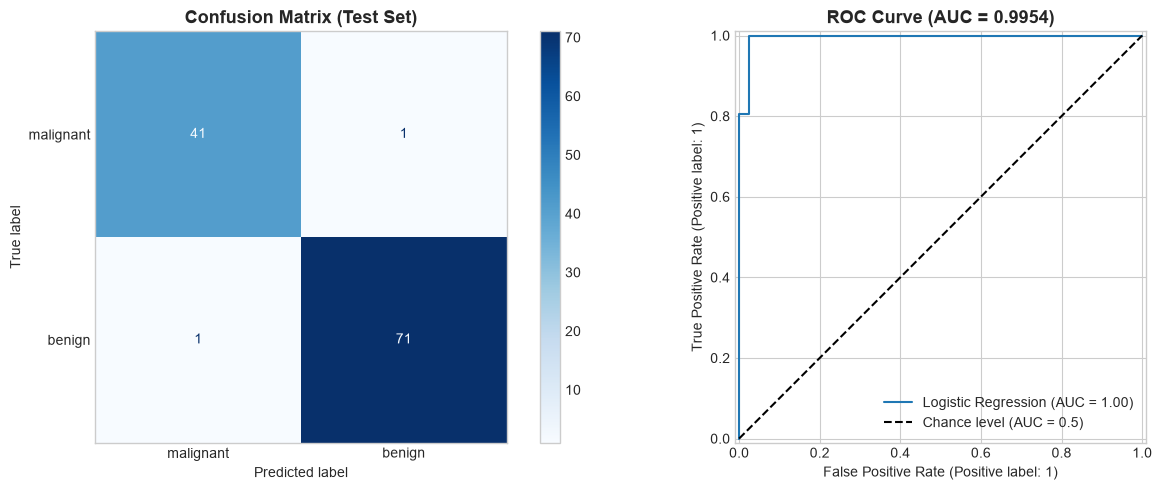

In [12]:
# Visual Evaluation: Confusion Matrix & ROC Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Display
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=raw_dataset.target_names,
    cmap="Blues",
    ax=axes[0]
)
axes[0].set_title("Confusion Matrix (Test Set)", fontsize=13, fontweight="bold")
axes[0].grid(False)

# 2. ROC Curve Display
RocCurveDisplay.from_predictions(
    y_test,
    y_proba,
    name="Logistic Regression",
    plot_chance_level=True,
    ax=axes[1]
)
axes[1].set_title(f"ROC Curve (AUC = {test_roc_auc:.4f})", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()


## Step 6: Model Interpretability (Feature Coefficients)
Because our pipeline maintains feature tracking, we can extract the learned coefficients from the Logistic Regression model to see which features most strongly predict benign vs. malignant diagnoses.

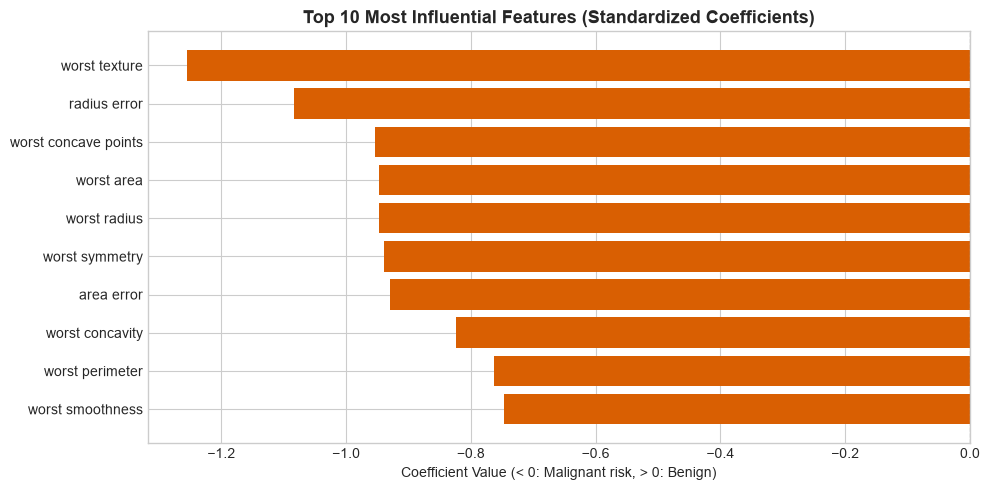

,Feature,Coefficient
21,worst texture,-1.255088
10,radius error,-1.082965
27,worst concave points,-0.953686
23,worst area,-0.947756
20,worst radius,-0.947616
28,worst symmetry,-0.939181
13,area error,-0.929104
26,worst concavity,-0.823151
22,worst perimeter,-0.763220
24,worst smoothness,-0.746625


In [13]:
# Extract coefficients and feature names from the fitted pipeline
classifier = best_pipeline.named_steps["classifier"]
feature_names = best_pipeline.named_steps["preprocessor"].get_feature_names_out()
clean_names = [name.split("__")[-1] for name in feature_names]
coefficients = classifier.coef_[0]

# Rank features by absolute magnitude of their coefficient
coef_df = pd.DataFrame({
    "Feature": clean_names,
    "Coefficient": coefficients,
    "Absolute_Impact": np.abs(coefficients)
}).sort_values(by="Absolute_Impact", ascending=False).head(10)

# Plot top 10 features
plt.figure(figsize=(10, 5))
colors = ["#d95f02" if c < 0 else "#1b9e77" for c in coef_df["Coefficient"]]
bars = plt.barh(coef_df["Feature"][::-1], coef_df["Coefficient"][::-1], color=colors[::-1])
plt.axvline(0, color="black", linestyle="--", linewidth=0.8)
plt.title("Top 10 Most Influential Features (Standardized Coefficients)", fontsize=13, fontweight="bold")
plt.xlabel("Coefficient Value (< 0: Malignant risk, > 0: Benign)")
plt.tight_layout()
plt.show()

display(coef_df[["Feature", "Coefficient"]])
